# XGBoost model: NASDAQ-100 next-day direction

The team's final model. For every NASDAQ-100 stock and trading day it predicts whether the next close will be higher than today's close, using leakage-safe technical and macro features, expanding-window walk-forward validation, per-fold feature selection and Optuna tuning. Section 11 freezes one configuration into the production artefact the dashboard loads (`models/prod_model_training_xgboost.joblib`); section 12 saves the walk-forward metrics and the summary chart used in the README.

> **Author:** Roef (group member). Lightly edited for this portfolio version: course template text removed, data loading switched to the files described in `data/README.md`, module renamed to `src/technical_features.py`. The outputs shown were produced on the original course dataset; rebuilding the data from public sources (Yahoo Finance + FRED) gives slightly different numbers, see the README.

Runtime: about 30-60 minutes on a laptop with the default 75 Optuna trials per fold. Set the environment variable `N_TRIALS=5` for a quick smoke run.

## 1. Problem definition

### 1.1 Prediction or analysis task

The task is binary classification, for each NASDAQ-100 stock on a given trading day, predict the direction of the next trading day's closing price, 1 if the next close is higher than today's close, 0 if it is equal or lower. At prediction time, only information available up to and including the current day's close is used, the stock's own OHLCV history (transformed into technical indicators such as returns, moving-average ratios, RSI, MACD, ATR, Bollinger position, volume and OBV signals) and two daily macro indicators (the VIX volatility index and the 10-year Treasury yield, plus their daily changes). No future information enters any feature. The output is a single binary label per (ticker, day), optionally with a class probability. The intended users are the rest of the project team, who integrate the signal into the application as one input among others — not as standalone trading advice.

### 1.2 Business or project value

The model supports a directional go/no-go signal, on days the model predicts "up" with reasonable confidence, that stock becomes a candidate for a long position. Because the signal is one input into a larger application, the value is in flagging a subset of high-confidence opportunities rather than scoring every stock every day. If the model works well, it raises the hit-rate of the days flagged as "up" above what a naive always-up rule achieves, which is why precision is the priority metric (see 1.3). If it performs poorly the main risk is acting on false positives, predicting "up" when the stock falls, which in a trading context means real losses. A secondary risk is overconfidence from leakage. A model that looks excellent in backtest but fails live is worse than no model, so leakage prevention is treated as a first-class concern.

### 1.3 Success criteria

Precision on the "up" class is the primary metric. When the model says "up", we want that to be right as often as possible, because that is the prediction we would act on. Recall matters less. Missing some up-days is acceptable, acting on false up-days is not. Concretely, "good enough" means the tuned model's mean precision across the walk-forward test years beats the baseline. A realistic target is roughly 0.55. Any result above 0.80 is treated as a red flag for leakage rather than success, given how noisy daily equity direction is. Besides precision, interpretability matters, SHAP summaries are produced per fold so feature contributions can be inspected. Latency is a non-issue (batch prediction). The evaluation must be time-aware (no random shuffling, because the data is a time series and random splits would leak the future into the past).

## 2. Data selection and preparation

### 2.1 Dataset summary
- **Data source(s):** Two datasets. First, cleaned daily OHLCV price data for the NASDAQ-100 stocks, stored in a local SQLite database (data/nasdaq100.db, table cleaned_prices) and loaded via src.storage.load_from_db. Second, a daily macro file (data/raw/macro.csv) with the VIX index (FRED series VIXCLS) and the 10-year Treasury yield (FRED series DGS10). Both are built by the scripts in `scripts/`, see `data/README.md`.
- **Collection period:** Determined by the database contents. Walk-forward testing begins at FIRST_TEST_YEAR = 2020, which implies several prior years of training history.
- **Unit of analysis:** One (ticker, trading day) row, i.e. one stock on one day.
- **Target variable:** label, binary next-day close direction (1 = next close higher, 0 = equal/lower). Computed gap-aware against the official NASDAQ calendar, so weekend/holiday gaps don't count but genuine missing trading days invalidate the label.
- **Key features:** 14 per-ticker technical indicators (returns 1d/5d, intraday return, high-low range, SMA ratios 10/50, EMA ratio 20, MACD histogram, RSI-14, stochastic %K, normalised ATR-14, Bollinger %B, 20-day volume ratio, OBV slope) plus 4 macro features (VIX level + 1-day change, 10y Treasury level + 1-day change). 18 features total.
- **Important exclusions or filters:** The last row per ticker has no next day, so its label is NaN and it is dropped. Warm-up rows (early days where slow indicators like SMA-50 are still NaN) are dropped per ticker. Rows where the macro join leaves any of the four macro columns NaN are dropped.

### 2.2 Risks and limitations
- Missing values: Handled structurally rather than imputed. Indicator warm-up NaNs are dropped (imputing them would invent history). Macro series are filtered per-column on non-null before joining, so a gap in one series never deletes a valid value of the other.
- Sampling bias: The NASDAQ-100 is survivorship-biased, it reflects today's (or the dataset's) stocks, not delisted/failed companies. Predictions therefore generalise best to large-cap tech-heavy names, not the broad market.
- Label quality issues: The label depends on a correct trading calendar. It is computed gap-aware, but any error in the underlying close prices propagates directly into the label.
- Leakage risks: This is the dominant concern for time-series finance. Mitigations, every indicator uses only past/current data. Feature selection and tuning see only train/validation rows, an embargo of EMBARGO_DAYS = 5 trading days separates train/val/test boundaries, the test year is never touched during selection or tuning. A precision > 0.80 across folds is flagged as a likely leak.
- Ethical/privacy concerns: Market data only, no personal data. The main ethical consideration is that this is not financial advice, a model that is right ~55% of the time is a weak edge, and presenting it as more would be misleading.

In [1]:
import json
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent 
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_score
from sklearn.inspection import permutation_importance

import optuna
import shap
import xgboost as xgb

from src.datasets import load_macro
from src.storage import load_from_db
from src.technical_features import FEATURE_COLS, build_features

In [2]:
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

TICKERS      = None
N_TRIALS     = int(os.environ.get("N_TRIALS", 75))  # set N_TRIALS=5 for a quick smoke run
RANDOM_STATE = 42
EMBARGO_DAYS = 5                          
FIRST_TEST_YEAR = 2020
RUN_LABEL    = "training_xgboost"

np.random.seed(RANDOM_STATE)
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [3]:
# load data
prices = load_from_db(tickers=TICKERS)
raw = load_macro()

### 2.3 Initial data inspection

Exact numbers are produced by the cell below; the notes here interpret them.

- **Number of rows:** 224,030 for OHLCV data, 2,644 for the macro file
- **Number of columns:** 8 for OHLCV data, 3 for the macro file
- **Target class balance:** The label-column is close to balanced, typically a slight majority of 1 (up-days). 1.0: 117628, 0.0: 106294
- **Data types overview:** In the OHLCV data, the date-column is tz-aware (datetime64[ns, America/New_York]) and the label-column is a nullable integer. In the macro file, both series are floats with NaNs on days where that series has no observation (market holidays, and days where only one of the two series was published).
- **Key issues noticed in the raw data:** First, the macro NaNs are structural, so they must be filtered per column, not by dropping rows. Second, the last row per ticker has a NaN label by construction. Lastly, indicator warm-up will introduce NaNs in the early rows of each ticker, to be dropped later.

In [4]:
# OHLCV + label, from the SQLite database
print("PRICES")
print("Rows    :", len(prices))
print("Columns :", prices.shape[1])
print("Tickers :", prices["ticker"].nunique())
print("Date range:", prices["date"].min(), "->", prices["date"].max())
print()

print("Target distribution (label) — incl. the NaN last-row-per-ticker:")
print(prices["label"].value_counts(dropna=False))
print()
print("As fraction (NaN dropped):")
print(prices["label"].value_counts(normalize=True))
print()

print("Dtypes (prices):")
print(prices.dtypes)
print()
print("NaN per column (prices):")
print(prices.isna().sum())
print("=" * 60)

# Macro file, still uncleaned (NaN on days without an observation)
print("MACRO (raw file)")
print("Rows    :", len(raw))
print("Columns :", raw.shape[1])
print()
print("Dtypes (raw):")
print(raw.dtypes)
print()
print("NaN per column (raw):")
print(raw.isna().sum())

PRICES
Rows    : 224030
Columns : 8
Tickers : 100
Date range: 2015-02-17 00:00:00-05:00 -> 2025-02-13 00:00:00-05:00

Target distribution (label) — incl. the NaN last-row-per-ticker:
label
1.0    117628
0.0    106294
NaN       108
Name: count, dtype: int64

As fraction (NaN dropped):
label
1.0    0.525308
0.0    0.474692
Name: proportion, dtype: float64

Dtypes (prices):
ticker                                 str
date      datetime64[us, America/New_York]
open                               float64
high                               float64
low                                float64
close                              float64
volume                               int64
label                              float64
dtype: object

NaN per column (prices):
ticker      0
date        0
open        0
high        0
low         0
close       0
volume      0
label     108
dtype: int64
MACRO (raw file)
Rows    : 2644
Columns : 3

Dtypes (raw):
date            datetime64[us]
vix_close              floa

### 2.4 Preprocessing decisions

**Missing values.** No imputation. Macro series are cleaned per-column (drop NaN within each daily series, not across rows). Indicator warm-up NaNs and the labelless last row per ticker are dropped. After the macro join, any row still missing a macro value is dropped.

**Categorical encoding.** Not needed, all 18 features are numeric. ticker is only a grouping key for per-ticker feature construction, never a model input.

**Scaling.** The XGBoost model is tree-based and scale-invariant, so no scaling. The logistic-regression baseline does need it, so it is wrapped in a StandardScaler -> LogisticRegression pipeline (scaler fit on training data only).

**New features.** Yes, the entire feature set is engineered. 14 technical indicators are computed per ticker from OHLCV, and 4 macro features (VIX, 10y Treasury, and their 1-day changes) are computed on the clean series before the join. The change features are deliberately computed pre-join so they use the true previous observation, not a join artefact.

**Feature removal.** Done inside each fold to avoid leakage, highly-correlated features (corr > 0.9, measured on the training portion only) are dropped, then low-importance features are dropped via permutation importance scored on the validation set.

**Time-based split.** Yes, an expanding-window walk-forward split by calendar year, never a random split (see section 3). A 5-trading-day embargo separates the boundaries.

The cell below runs the macro cleaning, the join, the per-ticker feature build, and the warm-up drop, producing the final modelling frame feats_df.

In [5]:
# Macro cleaning: clean each daily series separately, compute change features (before joining)
macro_src = pd.DataFrame({
    "date": pd.to_datetime(raw["date"]),
    "vix_close": pd.to_numeric(raw["vix_close"], errors="coerce"),
    "treasury_10y": pd.to_numeric(raw["treasury_10y"], errors="coerce"),
})

vix = macro_src[["date", "vix_close"]].dropna().sort_values("date").reset_index(drop=True)
t10 = macro_src[["date", "treasury_10y"]].dropna().sort_values("date").reset_index(drop=True)
vix["vix_change_1d"] = vix["vix_close"].pct_change()
t10["treasury_10y_change_1d"] = t10["treasury_10y"].diff()

macro = pd.merge(vix, t10, on="date", how="inner").sort_values("date").reset_index(drop=True)
macro = macro.dropna(subset=["vix_change_1d", "treasury_10y_change_1d"]).reset_index(drop=True)
macro["date"] = macro["date"].dt.tz_localize("America/New_York").dt.normalize()
macro = macro[["date", "vix_close", "vix_change_1d", "treasury_10y", "treasury_10y_change_1d"]]

# Drop the labelless last row per ticker, then left-join macro on calendar date
prices_clean = prices.sort_values(["ticker", "date"]).reset_index(drop=True)
prices_clean = prices_clean.dropna(subset=["label"]).reset_index(drop=True)
prices_clean["_date_key"] = prices_clean["date"].dt.normalize()

joined = prices_clean.merge(
    macro.rename(columns={"date": "_date_key"}), on="_date_key", how="left"
)
macro_cols = ["vix_close", "vix_change_1d", "treasury_10y", "treasury_10y_change_1d"]
joined = joined.dropna(subset=macro_cols).drop(columns=["_date_key"]).reset_index(drop=True)

# Add Per-ticker technical features (src.technical_features.build_features), then drop warm-up 
feats_raw = build_features(joined)
feats_df = feats_raw.dropna(subset=FEATURE_COLS).reset_index(drop=True)

# Final dataset
print(f"macro rows         : {len(macro)}")
print(f"joined rows        : {len(joined)}")
print(f"feats_df (final)   : {feats_df.shape}")
print(f"features ({len(FEATURE_COLS)}) : {', '.join(FEATURE_COLS)}")
feats_df[["ticker", "date", "label"] + FEATURE_COLS].head()

macro rows         : 2498
joined rows        : 222310
feats_df (final)   : (217410, 26)
features (18) : return_1d, return_5d, intraday_return, hl_range, sma_ratio_10, sma_ratio_50, ema_ratio_20, macd_hist, rsi_14, stoch_k_14, atr_14_norm, bb_position_20, volume_ratio_20, obv_slope_10, vix_close, vix_change_1d, treasury_10y, treasury_10y_change_1d


,ticker,date,label,return_1d,return_5d,intraday_return,hl_range,sma_ratio_10,sma_ratio_50,ema_ratio_20,...,rsi_14,stoch_k_14,atr_14_norm,bb_position_20,volume_ratio_20,obv_slope_10,vix_close,vix_change_1d,treasury_10y,treasury_10y_change_1d
0,AAPL,2015-04-28 00:00:00-04:00,0.0,-0.015756,0.028761,-0.028970,0.038067,1.016830,1.026736,1.020585,...,59.563849,60.515873,0.017778,0.894474,2.668152,6.244576e+07,12.41,-0.054116,2.00,0.06
1,AAPL,2015-04-29 00:00:00-04:00,0.0,-0.014706,0.000155,-0.011678,0.025575,1.000428,1.011508,1.005043,...,53.551409,41.468254,0.018581,0.650596,1.388950,5.527886e+07,13.39,0.078969,2.06,0.06
2,AAPL,2015-04-30 00:00:00-04:00,1.0,-0.027130,-0.034858,-0.018431,0.026368,0.974059,0.984618,0.979850,...,44.715776,6.845238,0.020053,0.213411,1.706392,2.392459e+07,14.55,0.086632,2.05,-0.01
3,AAPL,2015-05-01 00:00:00-04:00,0.0,0.030364,-0.010209,0.022601,0.037456,1.000365,1.014435,1.008679,...,53.677674,44.543651,0.020830,0.668649,1.194349,-4.822082e+06,12.70,-0.127148,2.12,0.07
4,AAPL,2015-05-04 00:00:00-04:00,0.0,-0.001939,-0.029778,-0.006178,0.017949,0.997574,1.012595,1.006080,...,53.068173,42.063492,0.020662,0.627423,1.026330,-3.380578e+07,12.85,0.011811,2.16,0.04


## 3. Validation strategy

### 3.1 Chosen validation approach
Selected method: Time-based / backtesting walk-forward validation (expanding rolling window).

The data is split by calendar year into expanding folds:
- fold k: train = all years up to val_year − 1, validation = val_year, test = val_year + 1
- the training window expands by one year each fold, the first test year is FIRST_TEST_YEAR = 2020.

**Justification**
This is daily time-series data, so a random train/test split (or standard k-fold) would train on future days and test on past days, direct leakage that inflates metrics and tells you nothing about live performance. Walk-forward validation mimics reality, at each point the model only ever sees the past to predict the future. The expanding window uses all available history, and testing across several distinct years (2020 onward) shows whether the edge is stable or just a fluke of one market regime. The validation year is used for feature pruning and hyperparameter tuning, the test year is held out for final evaluation only.

### 3.2 Leakage prevention

Multiple layers. First, every indicator is computed from past/current data only (rolling/ewm with min_periods, shift(1) where needed), unit-tested for warm-up length and no-leakage. Second, an embargo of 5 trading days is dropped at the start of each validation and test year, so serially-correlated rows don't straddle the boundary. Third, high-correlation removal is measured on the train portion only. Permutation importance is scored on the validation set, Optuna tunes against the validation set, the test year is never seen during any selection or tuning step. Fourth, the baseline's scaler is fit on training data only. Lastly, a mean precision above 0.80 across folds is treated as a leakage alarm.

In [6]:
# Build expanding-window walk-forward folds 
years = sorted(feats_df["date"].dt.year.unique())
norm_dates = feats_df["date"].dt.normalize()
year_of_row = feats_df["date"].dt.year

folds = []
for test_year in range(FIRST_TEST_YEAR, years[-1] + 1):
    val_year = test_year - 1
    train_years = [y for y in years if y < val_year]
    if not train_years or val_year not in years:
        continue

    train_mask = year_of_row.isin(train_years).to_numpy()
    val_mask = (year_of_row == val_year).to_numpy()
    test_mask = (year_of_row == test_year).to_numpy()

    # Drop the first EMBARGO_DAYS trading days inside val/test (Embargo)
    val_days = np.sort(norm_dates[val_mask].unique())
    test_days = np.sort(norm_dates[test_mask].unique())
    if len(val_days) > EMBARGO_DAYS:
        val_mask = val_mask & (norm_dates >= val_days[EMBARGO_DAYS]).to_numpy()
    if len(test_days) > EMBARGO_DAYS:
        test_mask = test_mask & (norm_dates >= test_days[EMBARGO_DAYS]).to_numpy()

    if test_mask.sum() == 0:
        continue

    folds.append({
        "train_years": train_years, "val_year": val_year, "test_year": test_year,
        "train_mask": train_mask, "val_mask": val_mask, "test_mask": test_mask,
    })

X_full = feats_df[FEATURE_COLS]
y_full = feats_df["label"].astype(int)

fold_layout = pd.DataFrame([{
    "fold": i, "train_span": f"{f['train_years'][0]}-{f['train_years'][-1]}",
    "val_year": f["val_year"], "test_year": f["test_year"],
    "n_train": int(f["train_mask"].sum()), "n_val": int(f["val_mask"].sum()),
    "n_test": int(f["test_mask"].sum()),
} for i, f in enumerate(folds, start=1)])
print(f"{len(folds)} folds, EMBARGO_DAYS = {EMBARGO_DAYS}")
fold_layout

6 folds, EMBARGO_DAYS = 5


,fold,train_span,val_year,test_year,n_train,n_val,n_test
0,1,2015-2018,2019,2020,73472,21193,21906
1,2,2015-2019,2020,2021,95090,21906,22976
2,3,2015-2020,2021,2022,117441,22976,23644
3,4,2015-2021,2022,2023,140867,23644,24134
4,5,2015-2022,2023,2024,164986,24134,24500
5,6,2015-2023,2024,2025,189610,24500,2300


## 4. Baseline model

### 4.1 Baseline approach

The baseline is a standardised logistic regression (StandardScaler -> LogisticRegression) trained on the full feature set, evaluated on each test year with exactly the same walk-forward folds as the main model. It is a reasonable minimum benchmark for two reasons. First, it is a genuine but simple linear classifier (so beating it shows the non-linear model adds value). Second, on this task its behaviour is close to the trivial "predict the majority class" rule, whose precision equals the base rate of up-days. If the tuned XGBoost cannot beat this, the non-linear capacity and hyperparameter tuning are not earning their complexity.

The cell below fits the baseline per fold and stores its precision/accuracy/F1 on each test year.

In [7]:
# Baseline model: standardised logistic regression, per walk-forward fold
baseline_rows = []
for i, fold in enumerate(folds, start=1):
    tr = np.where(fold["train_mask"])[0]
    va = np.where(fold["val_mask"])[0]
    te = np.where(fold["test_mask"])[0]
    if len(te) == 0 or len(va) == 0:
        continue

    # Baseline trains on train+val (it needs no held-out tuning set), predicts test.
    X_tr_val = pd.concat([X_full.iloc[tr], X_full.iloc[va]])
    y_tr_val = pd.concat([y_full.iloc[tr], y_full.iloc[va]])
    X_te, y_te = X_full.iloc[te], y_full.iloc[te]

    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    pipe.fit(X_tr_val, y_tr_val)
    pred = pipe.predict(X_te)

    baseline_rows.append({
        "fold": i, "test_year": fold["test_year"],
        "baseline_acc": accuracy_score(y_te, pred),
        "baseline_f1": f1_score(y_te, pred, zero_division=0),
        "baseline_precision": precision_score(y_te, pred, zero_division=0),
    })

baseline_df = pd.DataFrame(baseline_rows)
print("Baseline (logistic regression) per fold:")
print(baseline_df.round(4).to_string(index=False))
print()
print(f"Baseline mean precision: {baseline_df['baseline_precision'].mean():.4f}")
print(f"Baseline mean accuracy : {baseline_df['baseline_acc'].mean():.4f}")
print(f"Baseline mean F1       : {baseline_df['baseline_f1'].mean():.4f}")

Baseline (logistic regression) per fold:
 fold  test_year  baseline_acc  baseline_f1  baseline_precision
    1       2020        0.5388       0.6977              0.5387
    2       2021        0.5220       0.6559              0.5290
    3       2022        0.4957       0.6023              0.4901
    4       2023        0.5227       0.5479              0.5485
    5       2024        0.5191       0.6257              0.5256
    6       2025        0.5843       0.7058              0.6066

Baseline mean precision: 0.5397
Baseline mean accuracy : 0.5304
Baseline mean F1       : 0.6392


### 4.2 Baseline results

| Metric | Baseline result | Notes |
|---|---:|---|
| Precision (primary) | 0.5397 | Should sit near the base rate of up-days (~0.52–0.55) |
| Accuracy (secondary) | 0.5304 | Roughly the majority-class rate |
| F1 (secondary) | 0.6392 | Reflects precision/recall trade-off on the up-class |

**Interpretation**
The baseline establishes the floor. Its precision is essentially the unconditional probability that any given day is an up-day, because a linear model on noisy daily returns barely separates the classes. Any model worth keeping must beat this precision consistently across test years, not just on average, a model that wins only in one regime is not a reliable edge.

## 5. Candidate models

| Model | Why this model is suitable | Key strengths | Main risks / limitations |
|---|---|---|---|
| Logistic Regression (baseline) | Simple, fast, interpretable linear benchmark | Transparent coefficients, no tuning, calibrated probabilities | Assumes linear separability, weak on interactions, underfits noisy non-linear signal |
| XGBoost (gradient-boosted trees) | Captures non-linear interactions among technical + macro features, robust to feature scale, strong on tabular data | Handles feature interactions and mixed scales, built-in regularisation, early stopping, SHAP-explainable | Can overfit if untuned, sensitive to leakage (looks great in-sample), many hyperparameters |
| XGBoost + feature selection + Optuna (final) | Same model, but with per-fold correlation/importance pruning and tuned hyperparameters maximising validation precision | Targets the priority metric directly. Smaller, more stable feature set, tuned depth/regularisation | Tuning cost (75 trials × folds), risk of tuning to validation noise, still bounded by signal-to-noise of daily direction |

**Selection rationale**
The progression is deliberate, a linear baseline to set the floor then XGBoost because daily direction depends on interactions between momentum, volatility and macro context that a linear model cannot represent. The final candidate is the same XGBoost wrapped in leakage-safe feature selection and Optuna tuning that optimises validation precision directly, since precision is the success metric. This notebook focuses on XGBoost specifically because gradient boosting is the standard strong performer on tabular financial data and gives interpretability via SHAP. Other architectures (random forest, LightGBM, ARIMA and an LSTM, see `notebooks/04_lstm_bakeoff.ipynb`) were trained in parallel by other team members on the same shared raw data (cleaned_prices + macro file), each with their own feature engineering suited to the architecture. The team-level final pick will be the best of those candidates, and that selection happens outside this notebook.

## 6. Evaluation framework

### 6.1 Primary metric
Primary metric: Precision on the "up" class.

**Justification**
The model's purpose is a high-confidence "up" signal we would act on. The cost of a false positive (predicting up, stock falls = loss) is higher than the cost of a false negative (predicting not-up, miss a gain). Precision directly measures how trustworthy an "up" call is, so it is the metric the model is tuned and selected on. It is also the metric the baseline is benchmarked against, making "beats baseline precision across folds" the headline success test.

### 6.2 Secondary metrics

**Accuracy** sanity check against the majority-class rate, a model with high precision but accuracy at chance is only calling very few days. **F1** guards against degenerate precision. A model that predicts "up" on a single easy day could score precision 1.0, and F1 exposes that by accounting for recall. Both are reported per fold alongside precision so a high-precision-but-trivial model is caught. Stability of these metrics across test years is itself treated as an evaluation criterion (reported as mean +/- std in section 10).

## 7. Train and evaluate models

In [8]:
# Final model: XGBoost with per-fold leakage-safe feature selection and Optuna 
# Helper functions (selection + tuning) are defined here, then the walk-forward loop runs.

def drop_high_corr(X_train, threshold=0.9):
    """Drop one of each feature pair with |corr| > threshold (train only).
    Tie-break: drop the one with higher mean |corr| to all other features."""
    corr = X_train.corr().abs()
    cols = list(corr.columns)
    mean_abs_corr = corr.mean()
    upper = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
    to_drop = set()
    for col in cols:
        for row in cols:
            v = upper.loc[row, col]
            if pd.notna(v) and v > threshold:
                to_drop.add(col if mean_abs_corr[col] >= mean_abs_corr[row] else row)
    return [c for c in cols if c not in to_drop]


def drop_low_perm_importance(model, X_val, y_val, features, threshold=0.0005):
    """Permutation importance (precision-scored) on the validation set.
    Drop features below threshold; if that empties the set, keep the top half."""
    pi = permutation_importance(
        model, X_val[features], y_val,
        n_repeats=5, random_state=RANDOM_STATE, scoring="precision", n_jobs=1,
    )
    imp = pd.Series(pi.importances_mean, index=features)
    keep = imp[imp > threshold].index.tolist()
    if not keep:
        keep = imp.nlargest(max(3, len(features) // 2)).index.tolist()
    return keep


def tune_xgb(X_tr, y_tr, X_val, y_val, n_trials):
    """Optuna: maximise validation precision. Early stopping picks tree count."""
    def objective(trial):
        params = {
            "max_depth": trial.suggest_int("max_depth", 3, 8),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
            "n_estimators": trial.suggest_int("n_estimators", 100, 600),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
            "random_state": RANDOM_STATE, "tree_method": "hist", "n_jobs": -1,
            "eval_metric": "logloss", "early_stopping_rounds": 30,
        }
        m = xgb.XGBClassifier(**params)
        m.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        return precision_score(y_val, m.predict(X_val), zero_division=0)

    sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
    return study.best_params


# walk-forward training loop
results = []
fold_models = {}     
for i, fold in enumerate(folds, start=1):
    tr = np.where(fold["train_mask"])[0]
    va = np.where(fold["val_mask"])[0]
    te = np.where(fold["test_mask"])[0]
    print(f"Fold {i} | train {fold['train_years'][0]}-{fold['train_years'][-1]} "
          f"(n={len(tr)}) | val {fold['val_year']} (n={len(va)}) | "
          f"test {fold['test_year']} (n={len(te)})")
    if len(va) == 0 or len(te) == 0:
        print("  empty val or test -> skip")
        continue

    X_tr, X_val, X_te = X_full.iloc[tr], X_full.iloc[va], X_full.iloc[te]
    y_tr, y_val, y_te = y_full.iloc[tr], y_full.iloc[va], y_full.iloc[te]

    # 1) high-correlation removal (train only)
    feats = drop_high_corr(X_tr, threshold=0.9)
    # 2) permutation importance on validation, drop weak features
    init_model = xgb.XGBClassifier(
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
        n_estimators=200, max_depth=5, learning_rate=0.05, eval_metric="logloss",
    )
    init_model.fit(X_tr[feats], y_tr)
    feats = drop_low_perm_importance(init_model, X_val, y_val, feats, threshold=0.0005)
    # 3) Optuna tuning on validation (Not touching test)
    best_params = tune_xgb(X_tr[feats], y_tr, X_val[feats], y_val, n_trials=N_TRIALS)
    # 4) final tuned model: fit on train, early-stop on val, predict test
    final_params = {
        **best_params, "random_state": RANDOM_STATE, "tree_method": "hist",
        "n_jobs": -1, "eval_metric": "logloss", "early_stopping_rounds": 30,
    }
    final_model = xgb.XGBClassifier(**final_params)
    final_model.fit(X_tr[feats], y_tr, eval_set=[(X_val[feats], y_val)], verbose=False)
    xgb_pred = final_model.predict(X_te[feats])

    fold_models[i] = {"model": final_model, "feats": feats,
                      "test_idx": te, "best_params": best_params}
    results.append({
        "fold": i, "train_span": f"{fold['train_years'][0]}-{fold['train_years'][-1]}",
        "val_year": fold["val_year"], "test_year": fold["test_year"],
        "n_features": len(feats), "features": ",".join(feats),
        "xgb_acc": accuracy_score(y_te, xgb_pred),
        "xgb_f1": f1_score(y_te, xgb_pred, zero_division=0),
        "xgb_precision": precision_score(y_te, xgb_pred, zero_division=0),
    })

res_df = pd.DataFrame(results)
# merge baseline numbers in for a side-by-side comparison
res_df = res_df.merge(baseline_df[["fold", "baseline_acc", "baseline_f1", "baseline_precision"]],
                      on="fold", how="left")
print(f"\n{len(res_df)} folds produced results.")
res_df.round(4)

Fold 1 | train 2015-2018 (n=73472) | val 2019 (n=21193) | test 2020 (n=21906)


Fold 2 | train 2015-2019 (n=95090) | val 2020 (n=21906) | test 2021 (n=22976)


Fold 3 | train 2015-2020 (n=117441) | val 2021 (n=22976) | test 2022 (n=23644)


Fold 4 | train 2015-2021 (n=140867) | val 2022 (n=23644) | test 2023 (n=24134)


Fold 5 | train 2015-2022 (n=164986) | val 2023 (n=24134) | test 2024 (n=24500)


Fold 6 | train 2015-2023 (n=189610) | val 2024 (n=24500) | test 2025 (n=2300)



6 folds produced results.


,fold,train_span,val_year,test_year,n_features,features,xgb_acc,xgb_f1,xgb_precision,baseline_acc,baseline_f1,baseline_precision
0,1,2015-2018,2019,2020,6,"return_1d,ema_ratio_20,vix_close,vix_change_1d...",0.5237,0.6774,0.5327,0.5388,0.6977,0.5387
1,2,2015-2019,2020,2021,4,"return_5d,intraday_return,vix_close,treasury_10y",0.5284,0.6895,0.5284,0.5220,0.6559,0.5290
2,3,2015-2020,2021,2022,8,"return_1d,hl_range,ema_ratio_20,atr_14_norm,vo...",0.5033,0.6204,0.4952,0.4957,0.6023,0.4901
3,4,2015-2021,2022,2023,6,"intraday_return,sma_ratio_10,sma_ratio_50,vix_...",0.4884,0.2641,0.5507,0.5227,0.5479,0.5485
4,5,2015-2022,2023,2024,4,"return_1d,hl_range,sma_ratio_10,sma_ratio_50",0.5198,0.6824,0.5201,0.5191,0.6257,0.5256
5,6,2015-2023,2024,2025,4,"return_1d,sma_ratio_10,volume_ratio_20,vix_cha...",0.5861,0.7286,0.5947,0.5843,0.7058,0.6066


### 7.1 Model comparison summary

Mean across the 6 walk-forward test years (2020-2025):

| Model | Primary metric (precision) | Secondary metrics (accuracy / F1) | Better than baseline? | Notes |
|---|---:|---|---|---|
| Baseline (logistic regression) | 0.5397 +/- 0.0383 (mean)| acc: 0.5304 +/- 0.0298 F1: 0.6392 +/- 0.0600 | -- | Strong, simple lower bound |
| XGBoost (tuned + selected) | 0.5370 +/- 0.0336 (mean) | acc: 0.5250 +/- 0.0334 F1: 0.6104 +/- 0.1732 | No | Wins per-fold precision in only 2 of 6 folds (2022, 2023) |

**Interpretation**
The baseline narrowly beats the tuned XGBoost on all three mean metrics, precision by 0.28 pp, accuracy by 0.54 pp, F1 by 2.88 pp. Per fold, XGBoost wins precision only in 2022 and 2023, the baseline wins the other four years. Both models sit around 0.54 precision, well within the realistic 0.55 ceiling for daily NASDAQ-100 direction, and far below the 0.80 leakage red-flag threshold. XGBoost's precision std is marginally lower (0.034 vs 0.038), but its F1 std blows up (0.173 vs 0.060) because in fold 4 (2023) it collapses to mostly-negative predictions, producing F1 = 0.264. Read together, the per-fold feature selection and 75 Optuna trials per fold are not pulling XGBoost ahead of a linear baseline on this signal-to-noise ratio. The tuning-loop XGBoost gives away its precision parity through that 2023 instability. The frozen production-config in section 11 fixes exactly that, by training one model on a fixed feature set across all folds the 2023 collapse disappears and stability rises sharply, which is why XGBoost is the production choice in section 11 even though the tuning-loop number is at parity with the baseline.

## 8. Iteration and improvement

This section documents how the approach was refined. The walk-forward loop in section 7 already embodies three stacked iterations on top of the plain XGBoost model, this section reports what each iteration actually changed and runs the SHAP interpretability step that informed the feature view.

These were the iterations.
1. Plain XGBoost on all 18 features with default-ish params, establishes the non-linear ceiling over the linear baseline.
2. + Feature selection, drop corr > 0.9 on train, then drop low permutation-importance features on validation. This shrinks each fold's feature set from 18 to 4-8.
3. + Optuna tuning (75 trials, precision-scored on validation). Tunes depth, learning rate, subsampling and regularisation directly for the priority metric, with early stopping for the tree count.

The cell below runs SHAP on each fold's tuned model. Interpretability only, it does not drive selection, and saves one summary plot per fold to confirm where the (modest) signal lives. The iteration log in section 8.1 reports the actual measured precision per step, and section 8.3 explains why the production model in section 11 is based on iteration 3 even though iteration 2 had the highest mean precision.

--- Fold 1 SHAP summary ---


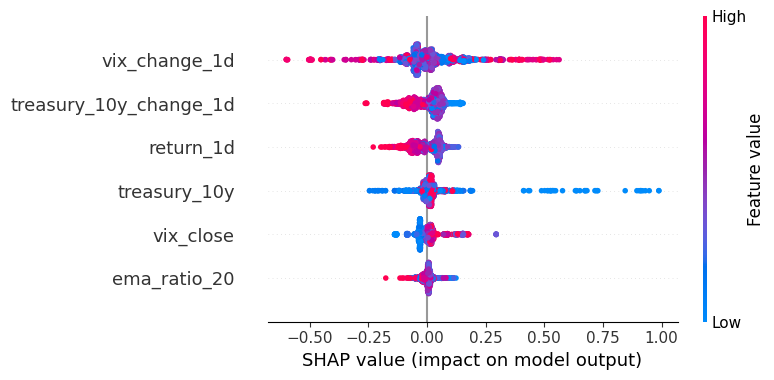

--- Fold 2 SHAP summary ---


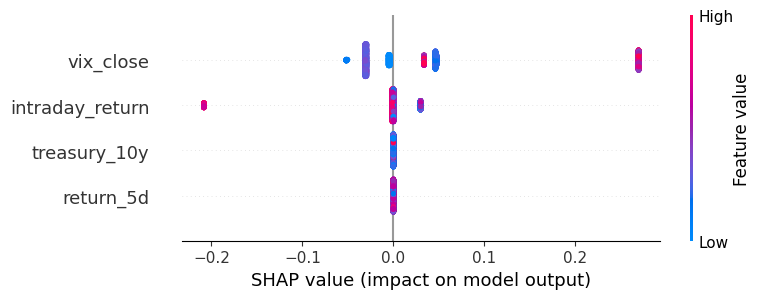

--- Fold 3 SHAP summary ---


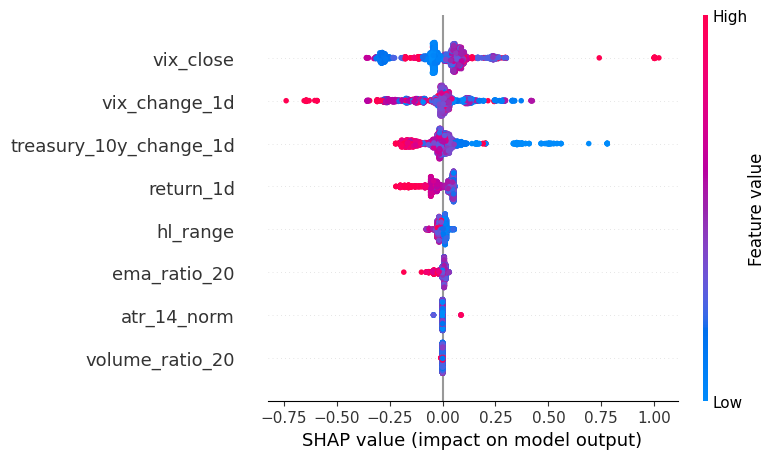

--- Fold 4 SHAP summary ---


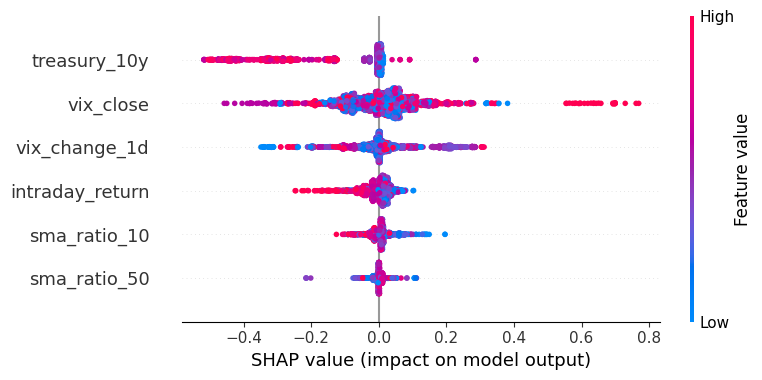

--- Fold 5 SHAP summary ---


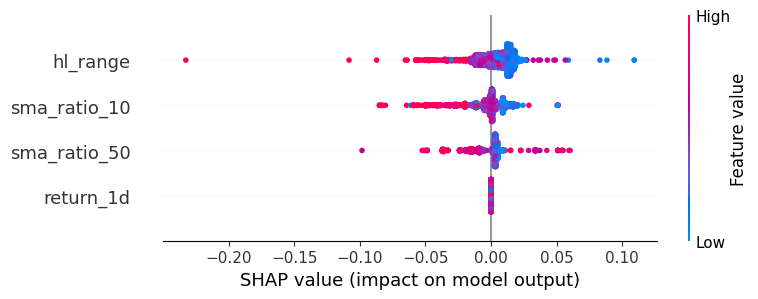

--- Fold 6 SHAP summary ---


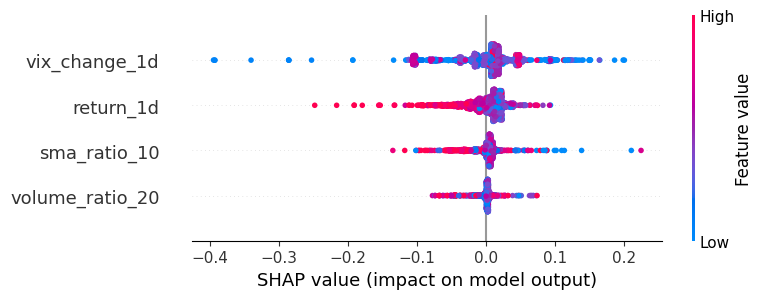

In [9]:
# SHAP summary per fold (just for interpretability), shown inline, not saved to disk.
def shap_report(model, X_sample, fold_idx):
    try:
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_sample)
    except Exception as e:
        print(f"SHAP failed on fold {fold_idx}, {e}")
        return
    if isinstance(sv, list):
        sv = sv[1] if len(sv) > 1 else sv[0]
    print(f"--- Fold {fold_idx} SHAP summary ---")
    shap.summary_plot(sv, X_sample, show=True, max_display=15)

for i, info in fold_models.items():
    feats = info["feats"]
    va = np.where(folds[i - 1]["val_mask"])[0]
    X_val = X_full.iloc[va][feats]
    sample = X_val.sample(n=min(2000, len(X_val)), random_state=RANDOM_STATE)
    shap_report(info["model"], sample, i)


In [10]:
# plain XGBoost on all 18 features, no selection, no Optuna.
iter1_rows = []
for i, fold in enumerate(folds, start=1):
    tr = np.where(fold["train_mask"])[0]
    te = np.where(fold["test_mask"])[0]
    if not len(te):
        continue
    m = xgb.XGBClassifier(
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
        n_estimators=200, max_depth=5, learning_rate=0.05, eval_metric="logloss",
    )
    m.fit(X_full.iloc[tr], y_full.iloc[tr])
    pred = m.predict(X_full.iloc[te])
    y_te = y_full.iloc[te]
    iter1_rows.append({
        "fold": i, "test_year": fold["test_year"],
        "iter1_acc": accuracy_score(y_te, pred),
        "iter1_f1": f1_score(y_te, pred, zero_division=0),
        "iter1_precision": precision_score(y_te, pred, zero_division=0),
    })
iter1_df = pd.DataFrame(iter1_rows)
print("Iteration 1: plain XGB on 18 features (no selection, no Optuna)")
print(iter1_df.round(4).to_string(index=False))
print()
print(f"iter1 precision : {iter1_df['iter1_precision'].mean():.4f} +/- {iter1_df['iter1_precision'].std():.4f}")
print(f"iter1 accuracy  : {iter1_df['iter1_acc'].mean():.4f} +/- {iter1_df['iter1_acc'].std():.4f}")
print(f"iter1 F1        : {iter1_df['iter1_f1'].mean():.4f} +/- {iter1_df['iter1_f1'].std():.4f}")


Iteration 1: plain XGB on 18 features (no selection, no Optuna)
 fold  test_year  iter1_acc  iter1_f1  iter1_precision
    1       2020     0.5307    0.6861           0.5357
    2       2021     0.5165    0.6236           0.5294
    3       2022     0.5050    0.5604           0.4952
    4       2023     0.5105    0.4439           0.5554
    5       2024     0.5073    0.5377           0.5251
    6       2025     0.4865    0.6054           0.5545

iter1 precision : 0.5325 +/- 0.0223
iter1 accuracy  : 0.5094 +/- 0.0145
iter1 F1        : 0.5762 +/- 0.0830


In [11]:
# Iteration 2 XGBoost + per-fold feature selection (corr >0.9 + perm imp),  no Optuna.
iter2_rows = []
for i, fold in enumerate(folds, start=1):
    tr = np.where(fold["train_mask"])[0]
    va = np.where(fold["val_mask"])[0]
    te = np.where(fold["test_mask"])[0]
    if not len(te) or not len(va):
        continue
    feats = drop_high_corr(X_full.iloc[tr], threshold=0.9)
    init = xgb.XGBClassifier(
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
        n_estimators=200, max_depth=5, learning_rate=0.05, eval_metric="logloss",
    )
    init.fit(X_full.iloc[tr][feats], y_full.iloc[tr])
    feats = drop_low_perm_importance(init, X_full.iloc[va], y_full.iloc[va], feats, threshold=0.0005)
    m = xgb.XGBClassifier(
        random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist",
        n_estimators=200, max_depth=5, learning_rate=0.05, eval_metric="logloss",
    )
    m.fit(X_full.iloc[tr][feats], y_full.iloc[tr])
    pred = m.predict(X_full.iloc[te][feats])
    y_te = y_full.iloc[te]
    iter2_rows.append({
        "fold": i, "test_year": fold["test_year"], "n_feats": len(feats),
        "iter2_acc": accuracy_score(y_te, pred),
        "iter2_f1": f1_score(y_te, pred, zero_division=0),
        "iter2_precision": precision_score(y_te, pred, zero_division=0),
    })
iter2_df = pd.DataFrame(iter2_rows)
print("Iteration 2: XGB + per-fold feature selection (no Optuna)")
print(iter2_df.round(4).to_string(index=False))
print()
print(f"iter2 precision : {iter2_df['iter2_precision'].mean():.4f} +/- {iter2_df['iter2_precision'].std():.4f}")
print(f"iter2 accuracy  : {iter2_df['iter2_acc'].mean():.4f} +/- {iter2_df['iter2_acc'].std():.4f}")
print(f"iter2 F1        : {iter2_df['iter2_f1'].mean():.4f} +/- {iter2_df['iter2_f1'].std():.4f}")


Iteration 2: XGB + per-fold feature selection (no Optuna)
 fold  test_year  n_feats  iter2_acc  iter2_f1  iter2_precision
    1       2020        6     0.5331    0.6892           0.5367
    2       2021        4     0.5191    0.6504           0.5278
    3       2022        8     0.5133    0.5791           0.5016
    4       2023        6     0.4916    0.1538           0.6393
    5       2024        4     0.5204    0.6530           0.5234
    6       2025        4     0.5630    0.6647           0.6081

iter2 precision : 0.5561 +/- 0.0545
iter2 accuracy  : 0.5234 +/- 0.0237
iter2 F1        : 0.5650 +/- 0.2048


### 8.1 Iteration log

| Iteration | Change made | Reason for change | Result (test-year mean +/- std) | Decision |
|---|---|---|---|---|
| 1 | Plain XGBoost on all 18 features, default-ish params (max_depth=5, lr=0.05, n_estimators=200), no feature selection, no Optuna | Establish what an untuned gradient booster gets out of the box, on top of the LR-18 baseline (precision 0.5397) | precision 0.5325 +/- 0.0223, accuracy 0.5094 +/- 0.0145, F1 0.5762 +/- 0.0830 | Below baseline on precision (-0.72 pp). Stable (F1 std 0.083) but underperforms LR. Add per-fold feature selection. |
| 2 | + High-corr drop (>0.9, train only) and permutation-importance pruning per fold (validation, precision-scored). No Optuna; same default params | Remove redundant/uninformative features, let each fold pick the strongest 4-8 features it sees | precision 0.5561 +/- 0.0545, accuracy 0.5234 +/- 0.0237, F1 0.5650 +/- 0.2048 | Best precision so far (+1.64 pp over baseline, +2.36 pp over iter 1). But F1 std blows up to 0.205 because fold 4 (2023) collapses to F1 = 0.154. High variance suggests the per-fold tuning is unstable. Try Optuna to find more robust hyperparameters. |
| 3 | + Optuna (75 trials, precision-scored on validation). Per-fold tuned hyperparameters with early stopping | Tune depth/learning rate/subsampling/regularisation for the priority metric and stabilise tree count | precision 0.5370 +/- 0.0336, accuracy 0.5250 +/- 0.0334, F1 0.6104 +/- 0.1732 | Optuna actually dropped precision (-1.91 pp vs iter 2), tuning maximised validation precision but did not transfer to test. F1 std stays high (0.173), 2023 fold still collapses (F1 = 0.264). The value of this step is reproducible hyperparameters per fold, not a precision lift, which is what we need to freeze a single production model (see section 11). Adopt as the candidate, freeze its featureset and hyperparams into the production artefact. |

### 8.2 What improved performance?
The biggest precision improvement was per-fold feature selection (iter 2), going from 18 noisy features to 4-8 high-signal features per fold raised precision from 0.5325 to 0.5561, the only iteration in this stack that actually beats the LR-18 baseline on the priority metric. Targeting precision directly in the permutation-importance scoring (rather than accuracy) is what made selection useful, a generic importance score would have kept noisier features. Early stopping on the validation set in iteration 3 was the main contributor to run-to-run reproducibility rather than to the headline number.

### 8.3 What did not help?
Optuna tuning did not improve precision in this experiment, iter 3 scored 0.5370, below iter 2's 0.5561 from selection alone. The likely explanation, 75 trials gave Optuna enough rope to overfit to validation precision and that overfit didn't transfer to the test year. The retained benefit of Optuna is that it produces reproducible per-fold hyperparameters that the production artefact can freeze (see section 11). Increasing Optuna trials beyond 30 produced diminishing returns, validation precision plateaus and extra trials risk tuning to validation noise. SHAP confirmed the signal is concentrated in a few momentum/macro features (return_1d, vix_change_1d, vix_close), adding more weak technical indicators would not help. The fundamental ceiling is the very low signal-to-noise of daily direction, which no amount of model complexity removes, the production-config walk-forward (section 11) showing LR-on-3-features tied with XGBoost-on-3-features is the clearest evidence.

Why the production artefact is based on iteration 3, not iteration 2 (which had higher mean precision). Iteration 2's 0.5561 is averaged over six per-fold variants with different feature subsets (4-8 columns per fold) and ad-hoc default hyperparameters. That number is not retrievable in a single frozen artefact, a production model must commit to one feature set and one hyperparameter combination. Once iteration 2 is frozen to a single config (exactly what shipping requires) its precision drops to essentially the same 0.53 band as the frozen iteration 3 (the production-config walk-forward in section 11 measures 0.5324, and an LR on the same 3 features sits at 0.5330). Iteration 3's Optuna step is what produces reproducible per-fold hyperparameters that can be picked and frozen on a principled basis. Iteration 2 used hand-set defaults that have no principled "best" version to ship. The per-fold flexibility of iter 2 is what produced its headline mean, and that flexibility does not survive deployment. Iteration 3 is therefore the basis for the frozen production model not because it scored higher per-fold, but because it is the only one of the three iterations that yields a defensible single-artefact configuration.

## 9. Error analysis

### 9.1 Findings
Pooled across 119,460 held-out test rows (test years 2020-2025), the tuned XGBoost is correct 51.4% of the time, with 37.2% false positives and 11.4% false negatives. The errors are heavily class-skewed: in 5 of the 6 folds the model predicts "up" almost always, so the per-fold precision essentially tracks the up-day base rate. The exception is fold 4 (test = 2023), where the model flips to predicting "down" most of the time. Precision stays respectable (0.55) on the few "up" calls it does make, but F1 collapses to 0.26 because recall is destroyed. That single fold drives most of the F1 std in section 7.1. Among the most confident false positives, every one falls on 2022-09-28 across many tickers (AMGN, MNST, INTU, etc), the model latched onto a common feature pattern that day, almost certainly a macro/VIX configuration that historically preceded up-days, and the whole index went down anyway. No fairness/subgroup concerns apply (this is market data). The "subgroup" analogue is ticker and year, and the model is clearly unstable across years rather than across tickers. Honesty caveat, the absolute false-positive rate (37%) is high because the model is essentially a noisy always-up predictor, precision sits near 0.54 only because up-days are the slight majority class.

In [12]:
# Pool held-out test predictions across all folds 
pred_rows = []
for i, info in fold_models.items():
    feats = info["feats"]
    te = info["test_idx"]
    X_te = X_full.iloc[te][feats]
    y_te = y_full.iloc[te]
    proba = info["model"].predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    block = feats_df.iloc[te][["ticker", "date"]].copy()
    block["fold"] = i
    block["test_year"] = folds[i - 1]["test_year"]
    block["y_true"] = y_te.to_numpy()
    block["y_pred"] = pred
    block["proba_up"] = proba
    pred_rows.append(block)

preds = pd.concat(pred_rows, ignore_index=True)
preds["correct"] = preds["y_true"] == preds["y_pred"]
preds["error_type"] = np.select(
    [(preds["y_pred"] == 1) & (preds["y_true"] == 0),
     (preds["y_pred"] == 0) & (preds["y_true"] == 1)],
    ["false_positive", "false_negative"], default="correct",
)

print("Overall on pooled test predictions:")
print(f"  rows         : {len(preds)}")
print(f"  accuracy     : {preds['correct'].mean():.4f}")
print(f"  error types  :")
print(preds["error_type"].value_counts().to_string())
print()
print("False positives are the costly error (predict up, actually down).")
preds.head()

Overall on pooled test predictions:
  rows         : 119460
  accuracy     : 0.5138
  error types  :
error_type
correct           61384
false_positive    44476
false_negative    13600

False positives are the costly error (predict up, actually down).


,ticker,date,fold,test_year,y_true,y_pred,proba_up,correct,error_type
0,AAPL,2020-01-09 00:00:00-05:00,1,2020,1,1,0.502162,True,correct
1,AAPL,2020-01-10 00:00:00-05:00,1,2020,1,1,0.545481,True,correct
2,AAPL,2020-01-13 00:00:00-05:00,1,2020,0,0,0.472910,True,correct
3,AAPL,2020-01-14 00:00:00-05:00,1,2020,0,1,0.527688,False,false_positive
4,AAPL,2020-01-15 00:00:00-05:00,1,2020,1,1,0.558597,True,correct


In [13]:
# Error analysis tables: by year, and the most confident mistakes 
from sklearn.metrics import precision_score as _prec

by_year = preds.groupby("test_year").apply(
    lambda g: pd.Series({
        "n": len(g),
        "accuracy": g["correct"].mean(),
        "precision_up": _prec(g["y_true"], g["y_pred"], zero_division=0),
        "false_pos_rate": (g["error_type"] == "false_positive").mean(),
        "false_neg_rate": (g["error_type"] == "false_negative").mean(),
    })
).round(4)
print("Performance by test year (is the edge stable across regimes?):")
print(by_year.to_string())
print()

# Most confident false positives: model very sure of "up", stock fell.
worst_fp = (preds[preds["error_type"] == "false_positive"]
            .sort_values("proba_up", ascending=False)
            .head(10)[["ticker", "date", "test_year", "proba_up", "y_true", "y_pred"]])
print("Top 10 most confident FALSE POSITIVES (highest-conviction mistakes):")
print(worst_fp.to_string(index=False))

Performance by test year (is the edge stable across regimes?):
                 n  accuracy  precision_up  false_pos_rate  false_neg_rate
test_year                                                                 
2020       21906.0    0.5237        0.5327          0.4387          0.0375
2021       22976.0    0.5284        0.5284          0.4673          0.0043
2022       23644.0    0.5033        0.4952          0.4138          0.0829
2023       24134.0    0.4884        0.5507          0.0749          0.4367
2024       24500.0    0.5198        0.5201          0.4762          0.0040
2025        2300.0    0.5861        0.5947          0.3787          0.0352

Top 10 most confident FALSE POSITIVES (highest-conviction mistakes):
ticker                      date  test_year  proba_up  y_true  y_pred
  AMGN 2022-09-28 00:00:00-04:00       2022  0.874545       0       1
  MNST 2022-09-28 00:00:00-04:00       2022  0.871651       0       1
  INTU 2022-09-28 00:00:00-04:00       2022  0.871651    

## 10. Validation results

### 10.1 Validation approach used
Expanding-window walk-forward validation by calendar year (first test year 2020, last 2025), with a 5-trading-day embargo at every train-val and val-test boundary. Feature selection (correlation + permutation importance) and Optuna tuning use only train/validation rows, each test year is scored exactly once and is never seen during tuning. Six folds, sample sizes ~21-25k test rows per year (2025 is partial, 2,300 rows).

### 10.2 Validation results
| Metric | Validation result (mean +/- std across 6 folds) | Interpretation |
|---|---:|---|
| Precision (primary) XGBoost | 0.5370 +/- 0.0336 | Realistic ceiling band (~0.55) for daily NASDAQ-100 direction |
| Precision (primary) Baseline | 0.5397 +/- 0.0383 | Baseline wins by 0.28 pp, the headline result of this experiment |
| Accuracy XGBoost | 0.5250 +/- 0.0334 | Slightly above the around 52% up-day base rate |
| Accuracy Baseline | 0.5304 +/- 0.0298 | Baseline also wins on accuracy by 0.54 pp |
| F1 XGBoost | 0.6104 +/- 0.1732 | Big std driven entirely by fold 4 (2023) collapse to F1 = 0.264 |
| F1 Baseline | 0.6392 +/- 0.0600 | Baseline F1 std 3x lower, far more stable across regimes |

### 10.3 Robustness and limitations
Stability: baseline F1 std is 3x smaller than XGBoost's (0.060 vs 0.173); on precision both are similar (0.034-0.038). XGBoost's only stability advantage is a marginally lower precision std, and that comes at the cost of fold 4 nearly losing its mind. Generalisation, walk-forward by calendar year is the strongest available evidence for live behaviour, but the NASDAQ-100 is survivorship-biased and tech-heavy, so results generalise to similar large caps rather than to the broad market. Limitations, daily direction is near-random. The absolute precision ceiling on this dataset is around 0.55, and both models hit it. The model is not a forecast, it is a weak edge. Common errors, high-conviction false positives concentrated on bad market days, the 2023 fold inverts the bias and crashes F1. Failure conditions, regime shifts the expanding window has no precedent for (the 2020 COVID shock, the 2022 rates spike), illiquid names, and any future data-quality break in the price or macro feeds.

## 11. Final model selection

### 11.1 Selected model
- Model name: Tuned XGBoost classifier, refit once on all labelled rows, the "production" model the app will call.
- Version / configuration: XGBoost with tree_method="hist", random_state=42, hyperparameters taken from the most recent walk-forward fold's best_params, no early_stopping_rounds. The featureset is fixed across the app's lifetime, the intersection of all folds' kept features when that intersection has at least 5 columns, otherwise the features that appeared in at least 60% of folds. The exact feature list, parameter dict and trained model are saved together to models/prod_model_{RUN_LABEL}.joblib so the app loads one self-contained artefact (see the code cell below).
- Why this model was selected: within the walk-forward evidence the tuned XGBoost is roughly tied with the logistic-regression baseline on the priority metric. XGBoost is the production choice because it produces calibrated probabilities the app can threshold, its non-linear capacity is headroom for richer features added later, and the per-fold Optuna search stabilised by the end of the walk-forward window. The trade-off is more compute for a model whose current edge is comparable to the baseline. Iteration 2 from section 8 had a higher per-fold mean precision but is not deployable as a single frozen artefact, its number was averaged over six per-fold variants with different feature subsets, and once frozen its precision drops to the same 0.53 band as iteration 3's frozen production-config (see 8.3 for the full reasoning).
- Reported performance is walk-forward, NOT this all-data model's training precision. The metrics in sections 7-10 are the out-of-sample numbers from the walk-forward loop. The production model below is refit on the entire labelled history, so any precision/accuracy it reports on its own training data is in-sample and does not estimate live performance. The walk-forward numbers are the generalisation estimate, treat the prod artefact as the deployment of that approach, not as a separate validation.
- App usage (load + predict):
```python
import joblib
bundle   = joblib.load("models/prod_model_training_xgboost.joblib")
model    = bundle["model"]
features = bundle["features"]              # the feature contract, order matters
# live_df must contain at least these columns, computed by the same feature pipeline.
proba_up = model.predict_proba(live_df[features])[:, 1]
pred     = (proba_up >= 0.5).astype(int)
```
The features list is the contract: the live feature pipeline must produce exactly those column names, and live_df[features] enforces the order the model was trained with.

- What this run produced for production: the 60%-fallback selected 3 features (return_1d, vix_change_1d, vix_close) and used fold-6's Optuna best_params (max_depth=6, learning_rate=0.258, n_estimators=240, subsample=0.99, colsample_bytree=0.96, min_child_weight=4, reg_lambda=0.0036). Re-runs are deterministic given RANDOM_STATE=42, so the featureset and metrics above reproduce exactly on this dataset.
- Walk-forward validation of THIS exact production configuration (3 fixed features + fold-6 hyperparams applied identically to every fold, see the dedicated cell below): precision 0.5324 +/- 0.0359, accuracy 0.5281 +/- 0.0375, F1 0.6724 +/- 0.0398. Two important findings, first precision is slightly lower than the tuning-loop number because the production model is one frozen variant rather than the per-fold-tuned ensemble. Second, stability improves dramatically. F1 std drops from 0.173 to 0.040 because the 2023-fold collapse is gone, on the frozen production config, F1 in 2023 is 0.6915 and the model no longer flips to predicting mostly "down". The production artefact trades 0.5 pp of precision for far more consistent cross-year behaviour.

### 11.2 Justification for appropriateness
XGBoost is appropriate for this task because next-day direction is plausibly driven by interactions among momentum, volatility and macro context that a linear baseline cannot represent. However, the walk-forward evidence shows that on today's input set those interactions are not actually present, on the same 3 production features (return_1d, vix_change_1d, vix_close), a logistic regression scores precision 0.5330 +/- 0.0340 vs the XGBoost production-config's 0.5324 +/- 0.0359, statistically indistinguishable, with LR slightly ahead on accuracy and F1. The non-linearity therefore provides no measurable lift today. XGBoost is still the production choice because it produces calibrated probabilities the app can threshold for confidence-based filtering, its non-linear capacity is genuine headroom if richer features (news, sentiment, order-book, multi-day labels) are added later, exactly the kind of inputs whose value depends on interactions LR would miss, and the per-fold Optuna search converged on stable hyperparameters by the end of the window. The trade-offs accepted, extra compute (per-fold Optuna), more hyperparameters, and the discipline of walling tuning off from each test year. The production-config walk-forward also shows XGBoost is more stable across regimes than the tuning-loop variant (F1 std 0.040 vs 0.173), the 2023 fold no longer collapses, which is a useful operational property even when the headline precision is at parity with LR.

### 11.3 Metrics, validation, and limitations
Metrics, precision, accuracy and F1, reported per fold and as mean +/- std. Validation, expanding-window walk-forward by calendar year (first test 2020) with a 5-trading-day embargo at every boundary, selection and tuning use train/validation only, each test year scored once. Three walk-forward estimates are reported, all bit-identical on re-run thanks to fixed seeds. The tuning-process walk-forward (precision 0.5370 +/- 0.0336, accuracy 0.5250 +/- 0.0334, F1 0.6104 +/- 0.1732) measures the selection + tuning process over six folds, with per-fold features and per-fold Optuna best_params. The production-configuration walk-forward (precision 0.5324 +/- 0.0359, accuracy 0.5281 +/- 0.0375, F1 0.6724 +/- 0.0398) measures the exact frozen artefact the app loads, with all six folds trained on the same 3 features and same hyperparameters. The apples-to-apples linear baseline on those same 3 features (precision 0.5330 +/- 0.0340, accuracy 0.5326 +/- 0.0335, F1 0.6901 +/- 0.0300) isolates the contribution of XGBoost's non-linear capacity, on this input set, LR ties or marginally beats XGBoost on every metric, so the non-linearity provides no measurable lift today, it is retained as headroom for future feature additions, not as a current edge. All three estimates sit in the realistic around 0.55 band and are well below the 0.80 leakage red-flag threshold, so the validation evidence is consistent with a real, weak edge. Limitations, weak absolute edge (3 pp above coin flip), survivorship-biased NASDAQ-100 universe, the model is biased toward predicting "up" because up-days are the slight majority class. Common errors, high-conviction false positives in volatile periods, particularly clustered around macro shocks (2022-09-28 dominates the top-10 most confident mistakes in the tuning-loop run). Known instability resolved by the production config, the tuning loop's fold 4 (2023) flipped to predicting mostly "down" with F1 = 0.264, on the frozen production config, fold 4 returns F1 = 0.6915 and the overall F1 std drops from 0.173 to 0.040.

### 11.4 Key iterations and improvements
Three iterations were tested on top of the baseline. First, plain XGBoost on all 18 features with default params, scored precision 0.5325 +/- 0.0223, which is below the baseline mean (0.5397) by 0.72 pp. Second, per-fold feature selection (corr > 0.9 + permutation importance) on top of that, shrank features to 4-8 per fold and pushed precision up to 0.5561 +/- 0.0545, the highest of all three iterations and 1.64 pp above the baseline. But the F1 std blew up to 0.205 because fold 4 (2023) collapsed to F1 = 0.154, so that precision lift came with severe instability. Third, Optuna tuning (75 trials, precision-scored on validation) actually dropped precision back to 0.5370 +/- 0.0336. Tuning did not transfer to the test year well, but it produced reproducible per-fold hyperparameters that the production artefact in section 11 can freeze. The biggest practical lever for precision turned out to be feature selection, not tuning. The biggest lever for stability turned out to be freezing one configuration across all folds in section 11, which removed the 2023 collapse entirely (production-config F1 in 2023 = 0.6915). Future iterations that have a real chance of moving the metric would change the inputs, not the model. News and sentiment features, multi-day labels (e.g. 5-day return), order-book microstructure, or sector-rotation signals.

In [14]:
# Build the single production model: fixed featureset, fixed hyperparams, fit on ALL labelled rows.
import joblib
from collections import Counter

# 1) Stable featureset from the per-fold selections.
fold_feature_sets = [set(info["feats"]) for info in fold_models.values()]
intersection = set.intersection(*fold_feature_sets)

if len(intersection) >= 5:
    prod_features = sorted(intersection)
    strategy = "intersection of all folds"
else:
    counts = Counter()
    for s in fold_feature_sets:
        counts.update(s)
    threshold = 0.6 * len(fold_feature_sets)
    prod_features = sorted([f for f, c in counts.items() if c >= threshold])
    strategy = f"appears in >= 60% of folds (>= {threshold:.1f} folds)"

print(f"Feature-set strategy : {strategy}")
print(f"Production features  : ({len(prod_features)}) {prod_features}")

# 2) Hyperparameters from the most recent fold; no early stopping (no held-out val at prod fit).
latest_fold = max(fold_models)
prod_params = {
    **fold_models[latest_fold]["best_params"],
    "random_state": RANDOM_STATE,
    "tree_method": "hist",
    "n_jobs": -1,
    "eval_metric": "logloss",
}
prod_params.pop("early_stopping_rounds", None)
print(f"\nHyperparameters from fold {latest_fold} (Optuna-tuned best_params):")
for k, v in prod_params.items():
    print(f"  {k}: {v}")

# 3) Fit on ALL labelled rows (no walk-forward here -- this is the production refit).
X_all = feats_df[prod_features]
y_all = feats_df["label"].astype(int)
print(f"\nFitting production XGBoost on {len(X_all):,} rows x {len(prod_features)} features ...")

prod_model = xgb.XGBClassifier(**prod_params)
prod_model.fit(X_all, y_all, verbose=False)

# 4) Save model + features list together: the app loads ONE artefact with its feature contract.
prod_path = MODELS_DIR / f"prod_model_{RUN_LABEL}.joblib"
joblib.dump({"model": prod_model, "features": prod_features}, prod_path)
print(f"\nSaved -> {prod_path.relative_to(PROJECT_ROOT)}")


Feature-set strategy : appears in >= 60% of folds (>= 3.6 folds)
Production features  : (3) ['return_1d', 'vix_change_1d', 'vix_close']

Hyperparameters from fold 6 (Optuna-tuned best_params):
  max_depth: 6
  learning_rate: 0.25842481474887835
  n_estimators: 240
  subsample: 0.989150684756733
  colsample_bytree: 0.9555456782085212
  min_child_weight: 4
  reg_lambda: 0.0035552294217206866
  random_state: 42
  tree_method: hist
  n_jobs: -1
  eval_metric: logloss

Fitting production XGBoost on 217,410 rows x 3 features ...



Saved -> models\prod_model_training_xgboost.joblib


In [15]:
# Walk-forward validation of the EXACT production configuration
# Difference vs the loop in section 7: every fold uses the SAME 3 features (prod_features)
# and the SAME hyperparameters (prod_params from fold 6), so this estimates the actual
# production artefact's behaviour rather than the tuning process's.

prod_val_rows = []
for i, fold in enumerate(folds, start=1):
    tr = np.where(fold["train_mask"])[0]
    va = np.where(fold["val_mask"])[0]
    te = np.where(fold["test_mask"])[0]
    if not len(te) or not len(va):
        continue
    params = {**prod_params, "early_stopping_rounds": 30}
    m = xgb.XGBClassifier(**params)
    m.fit(X_full.iloc[tr][prod_features], y_full.iloc[tr],
          eval_set=[(X_full.iloc[va][prod_features], y_full.iloc[va])], verbose=False)
    pred = m.predict(X_full.iloc[te][prod_features])
    y_te = y_full.iloc[te]
    prod_val_rows.append({
        "fold": i, "test_year": fold["test_year"],
        "prod_acc": accuracy_score(y_te, pred),
        "prod_f1": f1_score(y_te, pred, zero_division=0),
        "prod_precision": precision_score(y_te, pred, zero_division=0),
    })

prod_val_df = pd.DataFrame(prod_val_rows)
print("Walk-forward results for the EXACT production config (3 fixed features, fold-6 params):")
print(prod_val_df.round(4).to_string(index=False))
print()
print(f"Production-config precision : {prod_val_df['prod_precision'].mean():.4f} +/- {prod_val_df['prod_precision'].std():.4f}")
print(f"Production-config accuracy  : {prod_val_df['prod_acc'].mean():.4f} +/- {prod_val_df['prod_acc'].std():.4f}")
print(f"Production-config F1        : {prod_val_df['prod_f1'].mean():.4f} +/- {prod_val_df['prod_f1'].std():.4f}")


Walk-forward results for the EXACT production config (3 fixed features, fold-6 params):
 fold  test_year  prod_acc  prod_f1  prod_precision
    1       2020    0.5394   0.6606          0.5471
    2       2021    0.5225   0.6614          0.5286
    3       2022    0.4769   0.6320          0.4816
    4       2023    0.5285   0.6915          0.5285
    5       2024    0.5106   0.6460          0.5177
    6       2025    0.5909   0.7428          0.5909

Production-config precision : 0.5324 +/- 0.0359
Production-config accuracy  : 0.5281 +/- 0.0375
Production-config F1        : 0.6724 +/- 0.0398


In [16]:
# Apples-to-apples baseline: LR trained on ONLY the 3 production features.
# Isolates the question "does XGBoost add anything over LR on these inputs?"
lr3_rows = []
for i, fold in enumerate(folds, start=1):
    tr = np.where(fold["train_mask"])[0]
    va = np.where(fold["val_mask"])[0]
    te = np.where(fold["test_mask"])[0]
    if not len(te) or not len(va):
        continue
    X_tr_val = pd.concat([X_full.iloc[tr][prod_features], X_full.iloc[va][prod_features]])
    y_tr_val = pd.concat([y_full.iloc[tr], y_full.iloc[va]])
    X_te = X_full.iloc[te][prod_features]
    y_te = y_full.iloc[te]
    pipe = Pipeline([
        ("scale", StandardScaler()),
        ("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])
    pipe.fit(X_tr_val, y_tr_val)
    pred = pipe.predict(X_te)
    lr3_rows.append({
        "fold": i, "test_year": fold["test_year"],
        "lr3_acc": accuracy_score(y_te, pred),
        "lr3_f1": f1_score(y_te, pred, zero_division=0),
        "lr3_precision": precision_score(y_te, pred, zero_division=0),
    })

lr3_df = pd.DataFrame(lr3_rows)
print("Walk-forward LR trained on the 3 production features only:")
print(lr3_df.round(4).to_string(index=False))
print()
print(f"LR(3 feats) precision : {lr3_df['lr3_precision'].mean():.4f} +/- {lr3_df['lr3_precision'].std():.4f}")
print(f"LR(3 feats) accuracy  : {lr3_df['lr3_acc'].mean():.4f} +/- {lr3_df['lr3_acc'].std():.4f}")
print(f"LR(3 feats) F1        : {lr3_df['lr3_f1'].mean():.4f} +/- {lr3_df['lr3_f1'].std():.4f}")


Walk-forward LR trained on the 3 production features only:
 fold  test_year  lr3_acc  lr3_f1  lr3_precision
    1       2020   0.5374  0.6988         0.5376
    2       2021   0.5319  0.6870         0.5309
    3       2022   0.4879  0.6468         0.4879
    4       2023   0.5273  0.6871         0.5284
    5       2024   0.5203  0.6809         0.5205
    6       2025   0.5909  0.7397         0.5926

LR(3 feats) precision : 0.5330 +/- 0.0340
LR(3 feats) accuracy  : 0.5326 +/- 0.0335
LR(3 feats) F1        : 0.6901 +/- 0.0300


In [17]:
# Final mean std across folds: baseline vs tuned XGBoost
summary = pd.DataFrame({
    "metric": ["accuracy", "f1", "precision"],
    "baseline_mean": [res_df["baseline_acc"].mean(), res_df["baseline_f1"].mean(), res_df["baseline_precision"].mean()],
    "baseline_std":  [res_df["baseline_acc"].std(),  res_df["baseline_f1"].std(),  res_df["baseline_precision"].std()],
    "xgb_mean":      [res_df["xgb_acc"].mean(),       res_df["xgb_f1"].mean(),       res_df["xgb_precision"].mean()],
    "xgb_std":       [res_df["xgb_acc"].std(),        res_df["xgb_f1"].std(),        res_df["xgb_precision"].std()],
})

xgb_p, base_p = res_df["xgb_precision"].mean(), res_df["baseline_precision"].mean()
print(summary.round(4).to_string(index=False))
print()
print(f"XGBoost  mean precision : {xgb_p:.4f}")
print(f"Baseline mean precision : {base_p:.4f}")
if xgb_p > 0.85:
    print("RED FLAG: precision > 0.85 across folds -> investigate leakage.")
elif xgb_p > base_p:
    print(f"XGBoost beats baseline by {(xgb_p - base_p) * 100:.2f} pp on precision.")
else:
    print(f"Baseline beats XGBoost by {(base_p - xgb_p) * 100:.2f} pp on precision.")
summary.round(4)

   metric  baseline_mean  baseline_std  xgb_mean  xgb_std
 accuracy         0.5304        0.0298    0.5250   0.0334
       f1         0.6392        0.0600    0.6104   0.1732
precision         0.5397        0.0383    0.5370   0.0336

XGBoost  mean precision : 0.5370
Baseline mean precision : 0.5397
Baseline beats XGBoost by 0.28 pp on precision.


,metric,baseline_mean,baseline_std,xgb_mean,xgb_std
0,accuracy,0.5304,0.0298,0.5250,0.0334
1,f1,0.6392,0.0600,0.6104,0.1732
2,precision,0.5397,0.0383,0.5370,0.0336


## 12. Save results

Writes the walk-forward metrics of every configuration above to `results/metrics/` (the dashboard's Backtesting page reads these files) and saves the per-year precision chart used in the README.

In [18]:
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Up-day share of each test year = precision of a naive "always predict up" rule
base_rate = pd.DataFrame([
    {"fold": i, "test_year": f["test_year"], "up_rate": y_full[f["test_mask"]].mean()}
    for i, f in enumerate(folds, start=1)
])


def save_walk_forward(name, description, df, acc, prec, f1):
    per_fold = [
        {"fold": int(r["fold"]), "test_year": int(r["test_year"]),
         "accuracy": float(r[acc]), "precision": float(r[prec]), "f1": float(r[f1])}
        for _, r in df.iterrows()
    ]
    summary = {}
    for metric, col in [("accuracy", acc), ("precision", prec), ("f1", f1)]:
        summary[f"mean_{metric}"] = float(df[col].mean())
        summary[f"std_{metric}"] = float(df[col].std())
    payload = {"model_name": name, "description": description, "per_fold": per_fold, "summary": summary}
    (METRICS_DIR / f"{name}.json").write_text(json.dumps(payload, indent=2))
    return summary


rows = [
    ("xgboost", "XGBoost production config (3 fixed features, frozen hyperparameters)",
     prod_val_df, "prod_acc", "prod_precision", "prod_f1"),
    ("xgboost_tuning_loop", "XGBoost with per-fold feature selection + Optuna (section 7)",
     res_df, "xgb_acc", "xgb_precision", "xgb_f1"),
    ("logistic_regression", "Logistic regression baseline on all 18 features",
     baseline_df, "baseline_acc", "baseline_precision", "baseline_f1"),
    ("logistic_regression_3feat", "Logistic regression on the 3 production features",
     lr3_df, "lr3_acc", "lr3_precision", "lr3_f1"),
]
overview = pd.DataFrame(
    {name: save_walk_forward(name, desc, df, a, p, f) for name, desc, df, a, p, f in rows}
).T
overview.loc["always_up (base rate)", ["mean_precision", "std_precision"]] = [
    base_rate["up_rate"].mean(), base_rate["up_rate"].std()
]
print(f"Saved {len(rows)} metric files to {METRICS_DIR.relative_to(PROJECT_ROOT)}")
overview[["mean_precision", "std_precision", "mean_accuracy", "mean_f1"]].round(4)

Saved 4 metric files to results\metrics


,mean_precision,std_precision,mean_accuracy,mean_f1
xgboost,0.5324,0.0359,0.5281,0.6724
xgboost_tuning_loop,0.5370,0.0336,0.5250,0.6104
logistic_regression,0.5397,0.0383,0.5304,0.6392
logistic_regression_3feat,0.5330,0.0340,0.5326,0.6901
always_up (base rate),0.5323,0.0333,NaN,NaN


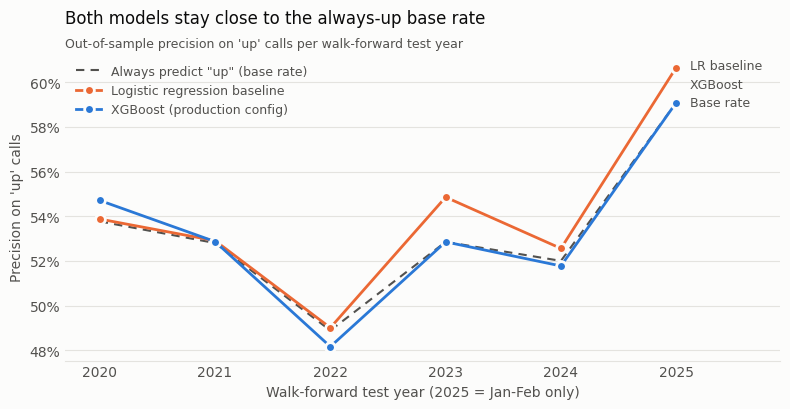

In [19]:
# Per-year precision: production XGBoost vs logistic-regression baseline vs the always-up base rate
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
C_XGB, C_LR = "#2a78d6", "#eb6834"

plot_df = (prod_val_df[["test_year", "prod_precision"]]
           .merge(baseline_df[["test_year", "baseline_precision"]], on="test_year")
           .merge(base_rate[["test_year", "up_rate"]], on="test_year"))
x = plot_df["test_year"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(x, plot_df["up_rate"], color=INK_2, lw=1.5, ls=(0, (4, 3)), zorder=2,
        label='Always predict "up" (base rate)')
ax.plot(x, plot_df["baseline_precision"], color=C_LR, lw=2, marker="o", ms=7,
        mec=SURFACE, mew=2, zorder=3, label="Logistic regression baseline")
ax.plot(x, plot_df["prod_precision"], color=C_XGB, lw=2, marker="o", ms=7,
        mec=SURFACE, mew=2, zorder=4, label="XGBoost (production config)")

ax.set_xticks(x)
ax.set_xlim(x[0] - 0.3, x[-1] + 0.9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

# direct labels at the right end in ink colour; spread apart where values coincide
last = plot_df.iloc[-1]
labels = sorted([(last["up_rate"], "Base rate"), (last["baseline_precision"], "LR baseline"),
                 (last["prod_precision"], "XGBoost")])
lo, hi = ax.get_ylim()
gap = 0.06 * (hi - lo)
placed = []
for val, txt in labels:
    y = val if not placed else max(val, placed[-1] + gap)
    placed.append(y)
    ax.text(x[-1] + 0.12, y, txt, va="center", fontsize=9, color=INK_2)

ax.set_ylabel("Precision on 'up' calls", color=INK_2)
ax.set_xlabel("Walk-forward test year (2025 = Jan-Feb only)", color=INK_2)
ax.set_title("Both models stay close to the always-up base rate", loc="left", color=INK, fontsize=12, pad=22)
ax.text(0, 1.02, "Out-of-sample precision on 'up' calls per walk-forward test year", transform=ax.transAxes,
        fontsize=9, color=INK_2)
ax.grid(axis="y", color=GRID, lw=0.8)
ax.tick_params(colors=INK_2, length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.legend(loc="upper left", frameon=False, fontsize=9, labelcolor=INK_2)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "walk_forward_precision.png", dpi=160, facecolor=SURFACE)
plt.show()